In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, classification_report
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# --- Cargar dataset Advertising ---
df = pd.read_csv('advertising.csv')

In [42]:
# ==========================================
# CONVERTIR Sales (continua) EN CATEGORÍAS
# ==========================================
# Bajo = 0 (Sales < mediana), Alto = 1 (Sales >= mediana)
mediana = df['Sales'].median()
df['Sales_cat'] = (df['Sales'] >= mediana).astype(int)

X = df[['TV', 'Radio', 'Newspaper']]
Y = df['Sales_cat']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# ==========================================
# SVM
# ==========================================
svm = SVC(kernel='linear')
svm.fit(X_train, Y_train)
Y_pred = svm.predict(X_test)

print("SVM")
print(f"Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")
print(classification_report(Y_test, Y_pred))

# ==========================================
# KNN
# ==========================================
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, Y_train)
Y_pred = knn.predict(X_test)

print("KNN")
print(f"Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")
print(classification_report(Y_test, Y_pred))

# ==========================================
# ÁRBOL DE DECISIÓN
# ==========================================
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, Y_train)
Y_pred = tree.predict(X_test)

print("ÁRBOL DE DECISIÓN")
print(f"Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")
print(classification_report(Y_test, Y_pred))

# ==========================================
# RANDOM FOREST
# ==========================================
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, Y_train)
Y_pred = rf.predict(X_test)

print("RANDOM FOREST")
print(f"Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")
print(classification_report(Y_test, Y_pred))

SVM
Accuracy: 0.9750
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        22
           1       0.95      1.00      0.97        18

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40

KNN
Accuracy: 0.9750
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        22
           1       0.95      1.00      0.97        18

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40

ÁRBOL DE DECISIÓN
Accuracy: 0.9750
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        22
           1       0.95      1.00      0.97        18

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        

Regresion lineal simple
Ecuación aprendida: Sales = 7.0071 + 0.0555*TV
Precisión del modelo (R² Score): 80.26%
Error Cuadrático Medio (MSE): 6.1011


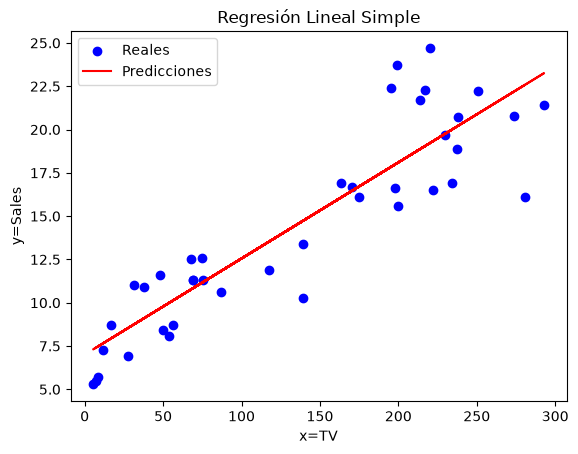

In [45]:
# REGRESIÓN LINEAL SIMPLE: TV -> Sales
# ==========================================
X = df[['TV']]
Y = df['Sales']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

#entrenamiento
model = LinearRegression()
model.fit(X_train, Y_train)

#prediccion
Y_pred = model.predict(X_test)

print("Regresion lineal simple")
print(f"Ecuación aprendida: Sales = {model.intercept_:.4f} + {model.coef_[0]:.4f}*TV")

r2 = r2_score(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)

print(f"Precisión del modelo (R² Score): {r2 * 100:.2f}%")
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")

plt.scatter(X_test, Y_test, color='blue', label='Reales')
plt.plot(X_test, Y_pred, color='red', label='Predicciones')
plt.title('Regresión Lineal Simple')
plt.xlabel('x=TV'); plt.ylabel('y=Sales'); plt.legend()
plt.show()


--- REGRESIÓN LINEAL MÚLTIPLE ---
Intercepto: 4.7141
  TV: 0.0545
  Radio: 0.1009
  Newspaper: 0.0043
Precisión del modelo (R² Score): 90.59%
Error Cuadrático Medio (MSE): 2.9078


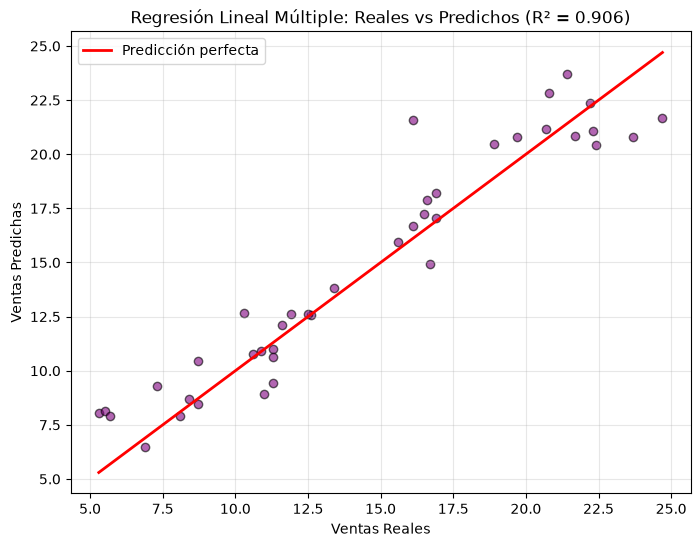

In [44]:
# ==========================================
# REGRESIÓN LINEAL MÚLTIPLE: TV + Radio + Newspaper -> Sales
# ==========================================
X = df[['TV', 'Radio', 'Newspaper']]
Y = df['Sales']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, Y_train)
Y_pred = model.predict(X_test)

# --- Cálculo de métricas ---
r2 = r2_score(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)

print("\n--- REGRESIÓN LINEAL MÚLTIPLE ---")
print(f"Intercepto: {model.intercept_:.4f}")
for col, coef in zip(X.columns, model.coef_):
    print(f"  {col}: {coef:.4f}")

# Métricas de precisión impresas claramente
print(f"Precisión del modelo (R² Score): {r2 * 100:.2f}%")
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")

# --- Gráfica Regresión Lineal Múltiple: Reales vs Predichos ---
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, Y_pred, color='purple', alpha=0.6, edgecolor='k')

# Línea ideal (Y_real = Y_pred)
min_val = min(Y_test.min(), Y_pred.min())
max_val = max(Y_test.max(), Y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linewidth=2, label='Predicción perfecta')

plt.title(f'Regresión Lineal Múltiple: Reales vs Predichos (R² = {r2:.3f})')
plt.xlabel('Ventas Reales')
plt.ylabel('Ventas Predichas')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()